# Exploração inicial: Matriz de Correlação, Box Plots e Gráficos de Dispersão

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.impute import SimpleImputer


In [ ]:
base_suppliers = pd.read_excel('supplier_recommender_textile (1).xlsx', sheet_name='SUPPLIERS')

Gráfico da distribuição do 'Average Rating' salvo como 'avg_rating_distribution.png'
Matriz de correlação (nível fornecedor) salva como 'correlation_matrix_supplier.png'
Gráfico de 'Average Rating' vs. cluster salvo como 'avg_rating_vs_cluster.png'
Gráfico de 'Average Rating' vs. region salvo como 'avg_rating_vs_region.png'
Gráfico de 'Average Rating' vs. tier salvo como 'avg_rating_vs_tier.png'
Gráfico de 'Average Rating' vs. performance_band salvo como 'avg_rating_vs_performance_band.png'
Gráfico de 'Average Rating' vs. product_focus salvo como 'avg_rating_vs_product_focus.png'
Gráfico de dispersão de 'Average Rating' vs. avg_lead_time_days salvo como 'avg_rating_vs_avg_lead_time_days_scatter.png'
Gráfico de dispersão de 'Average Rating' vs. price_index_vs_market salvo como 'avg_rating_vs_price_index_vs_market_scatter.png'
Gráfico de dispersão de 'Average Rating' vs. defect_rate_pct salvo como 'avg_rating_vs_defect_rate_pct_scatter.png'
Gráfico de dispersão de 'Average Rating' vs. su

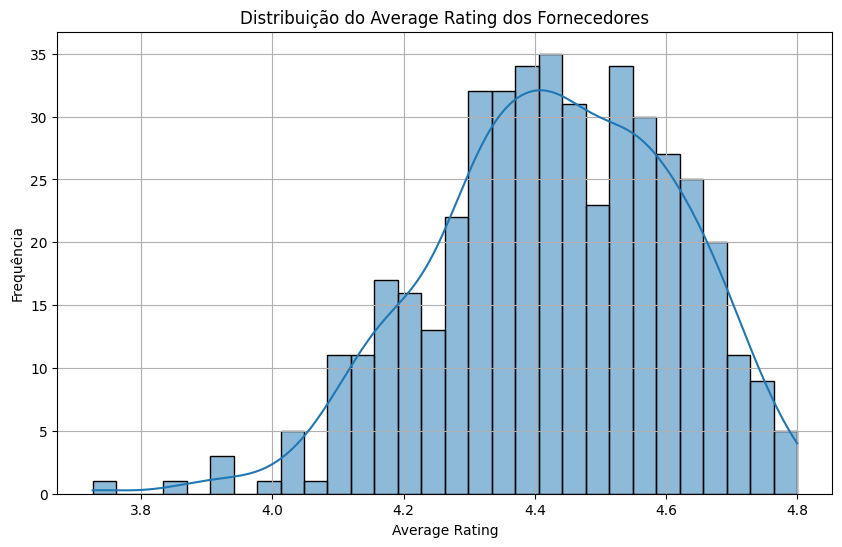

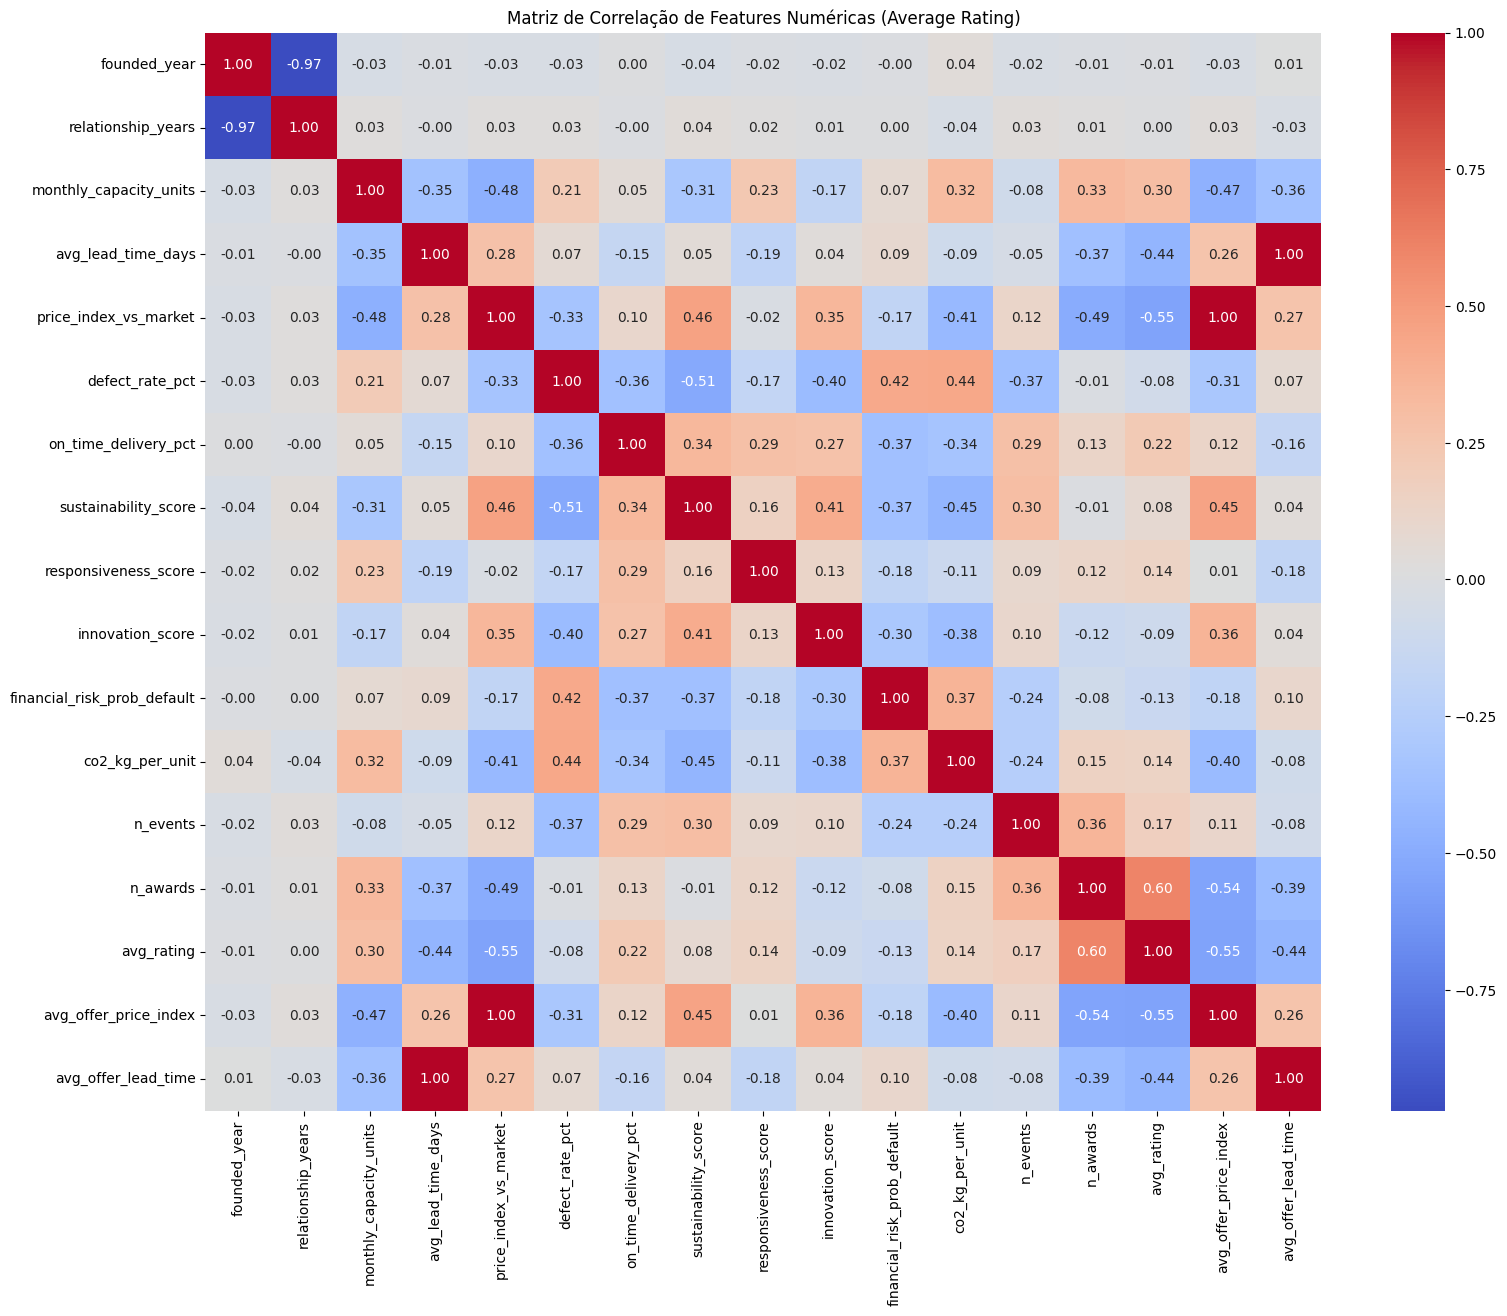

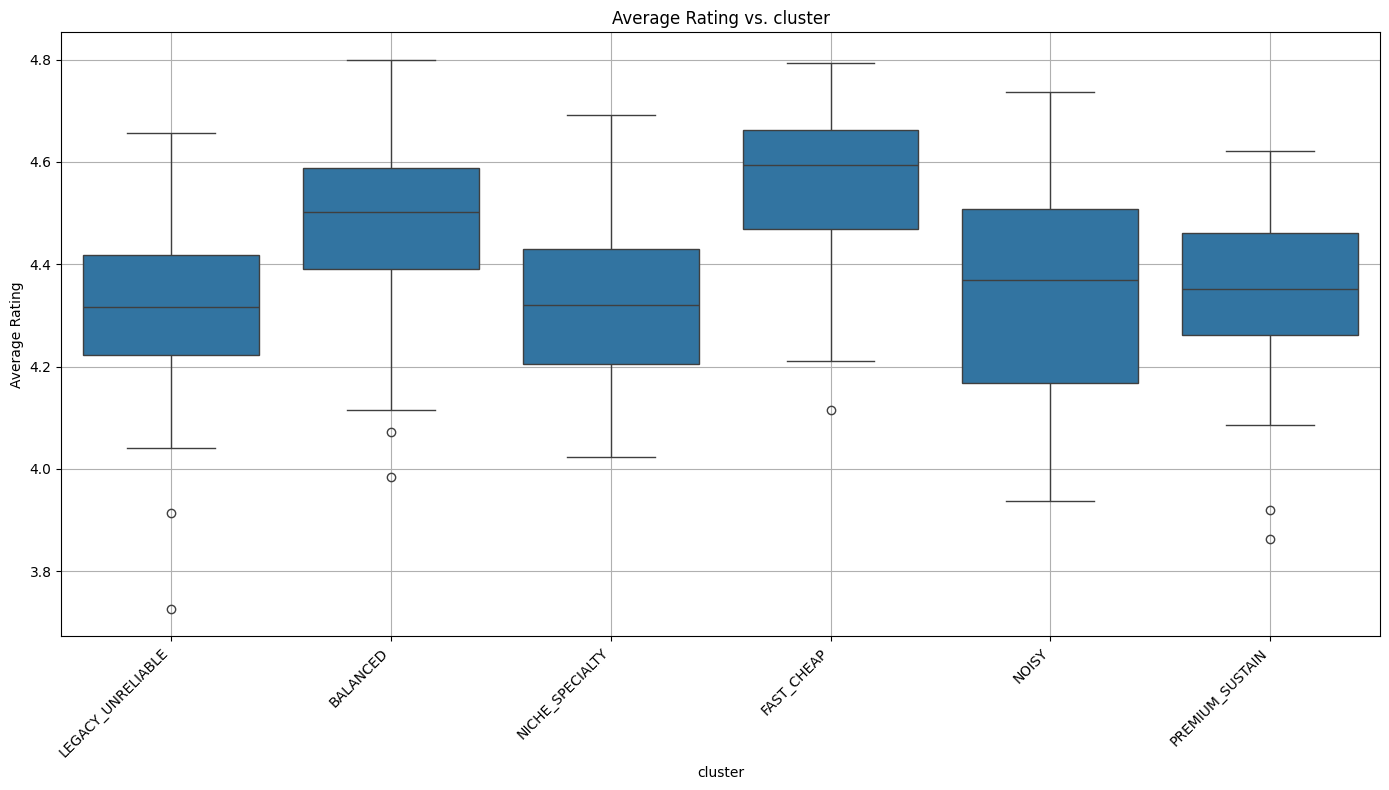

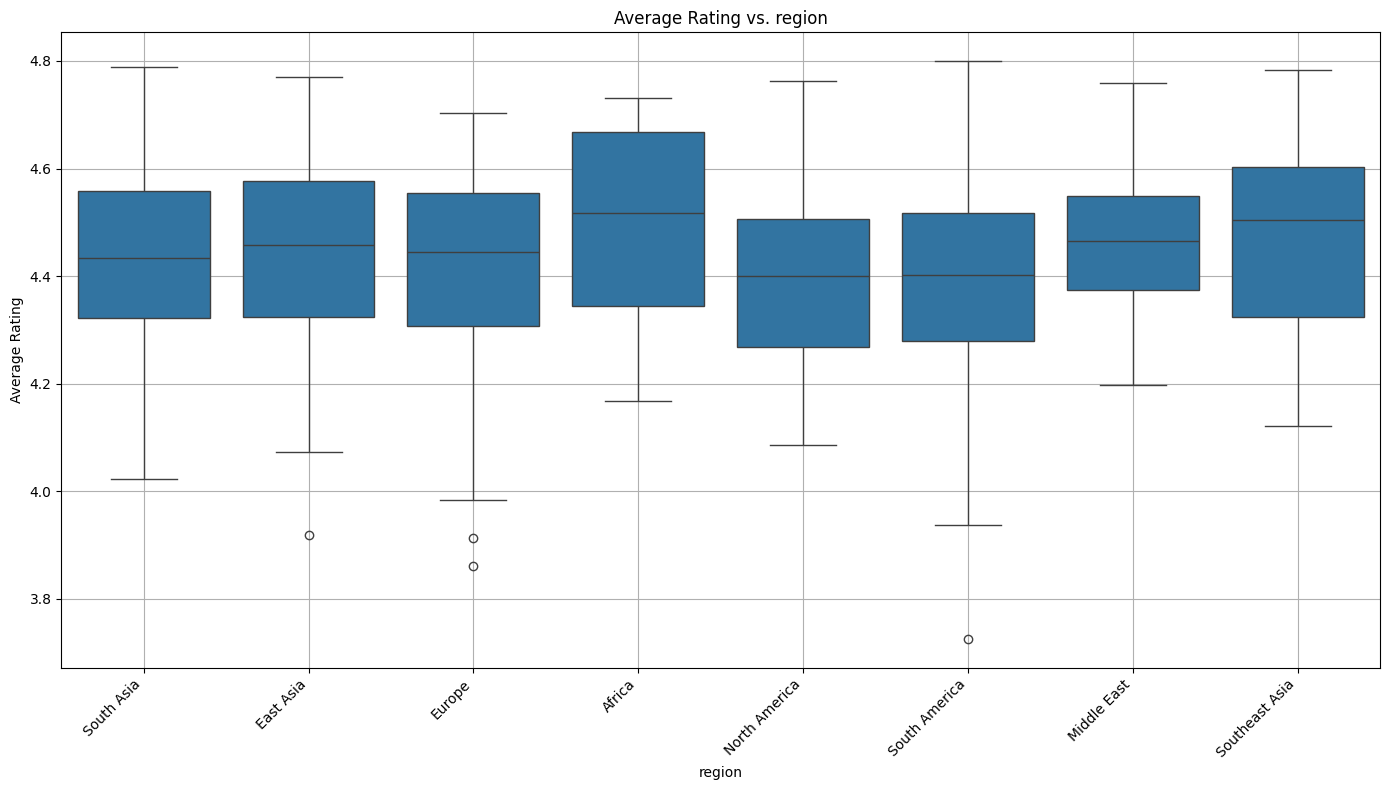

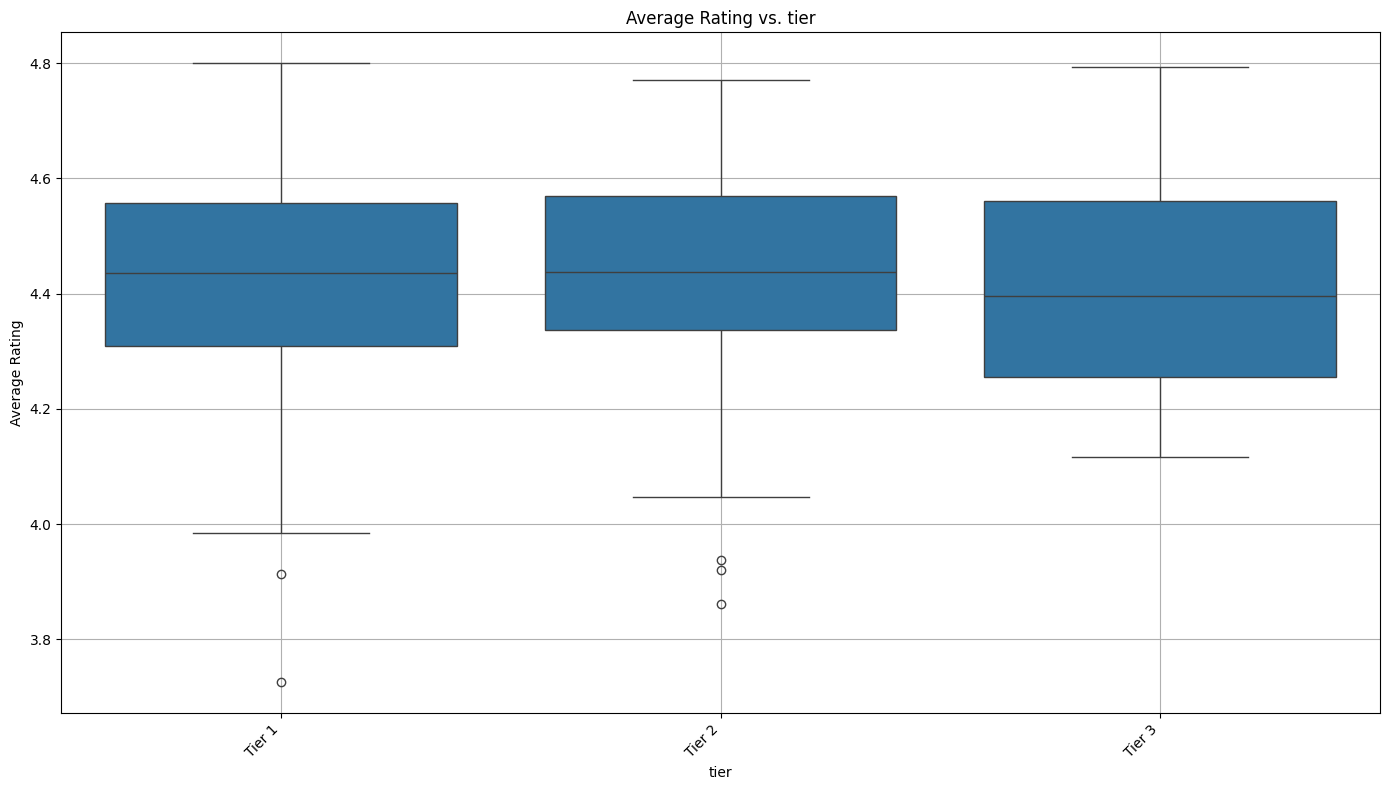

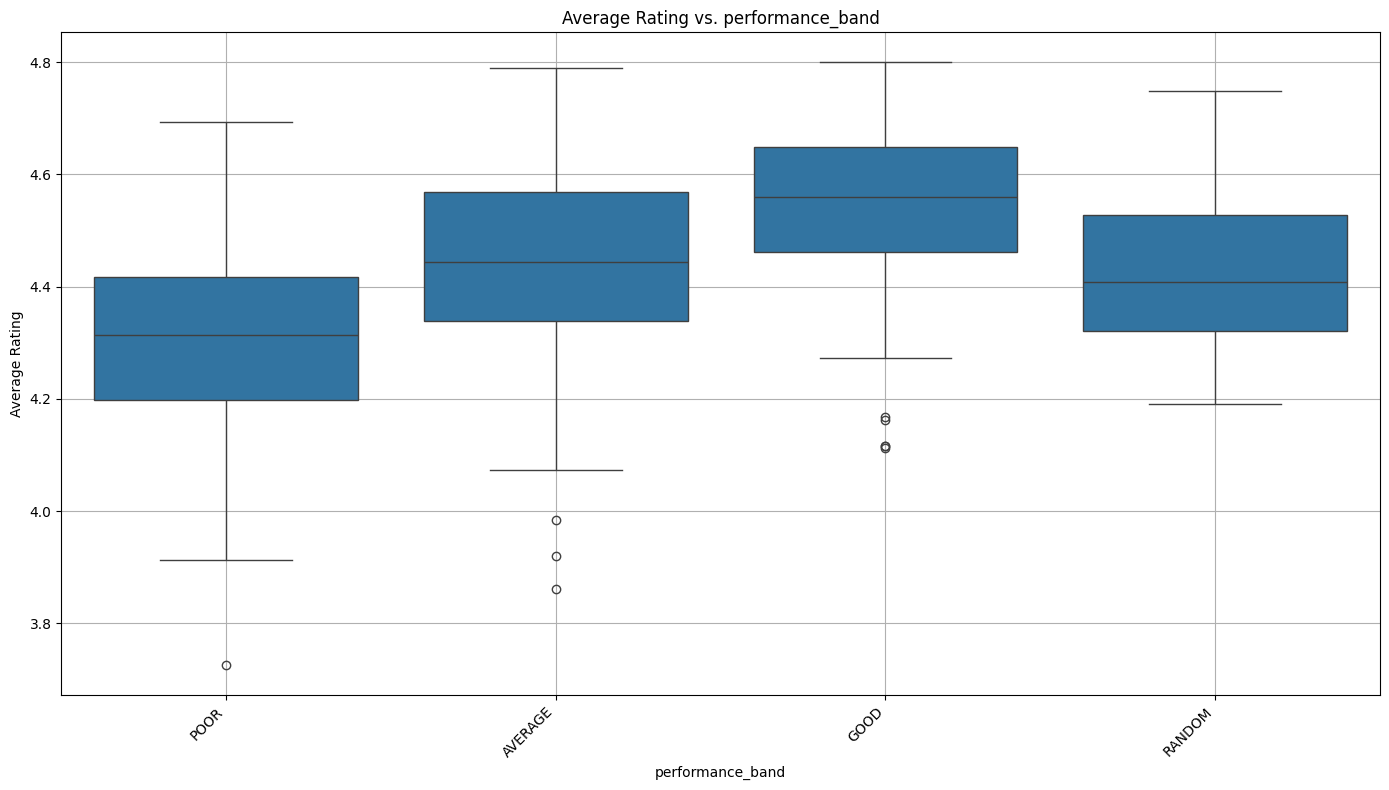

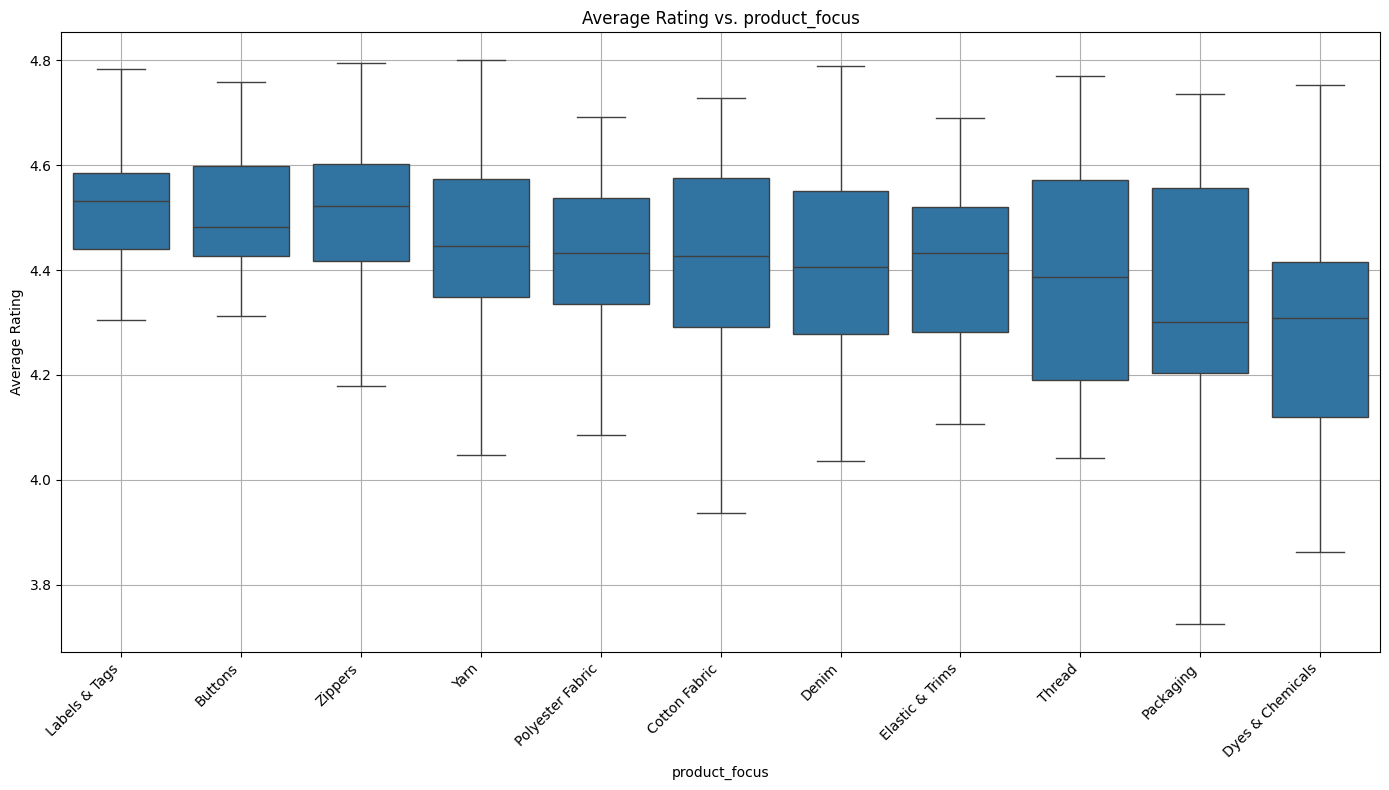

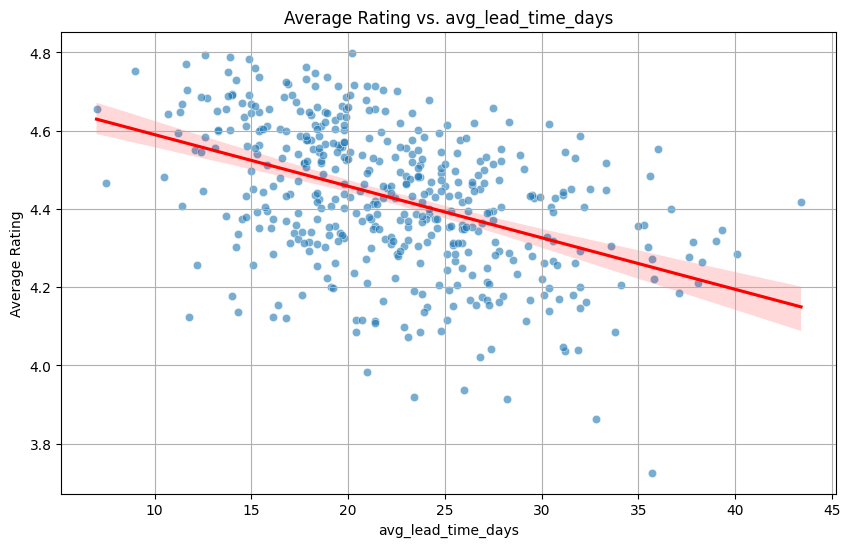

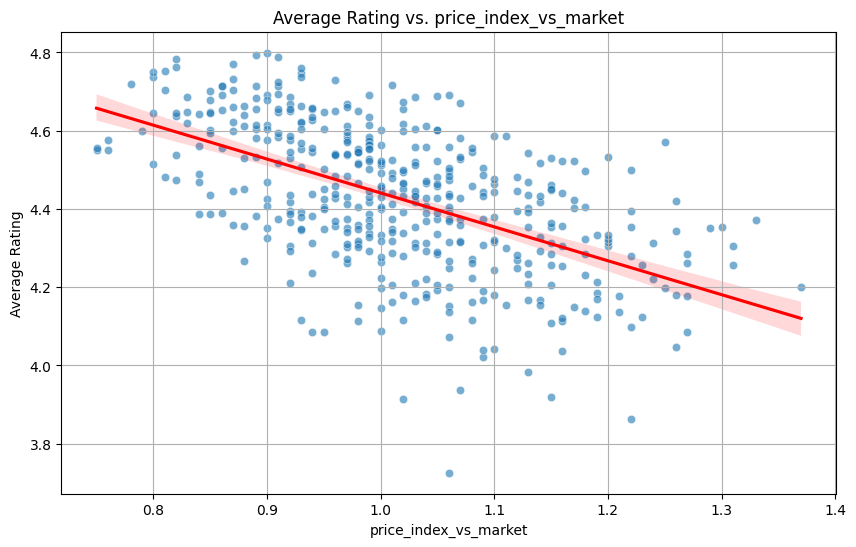

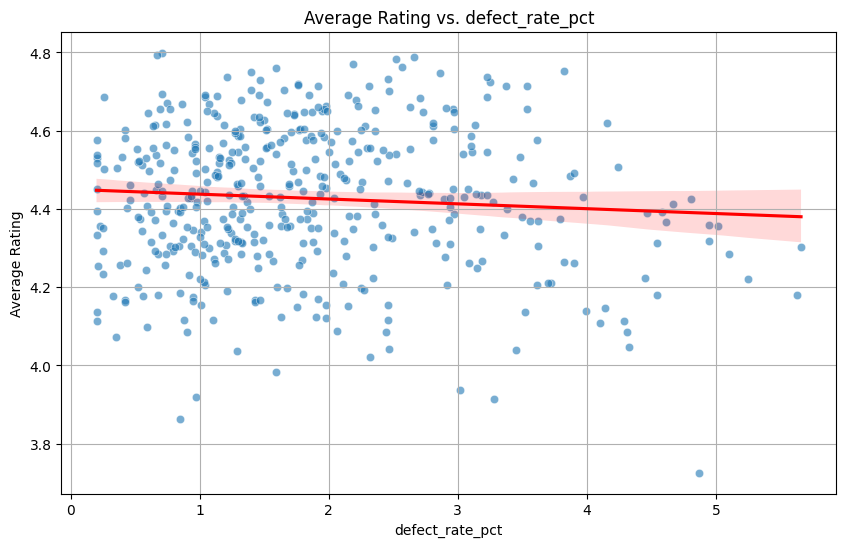

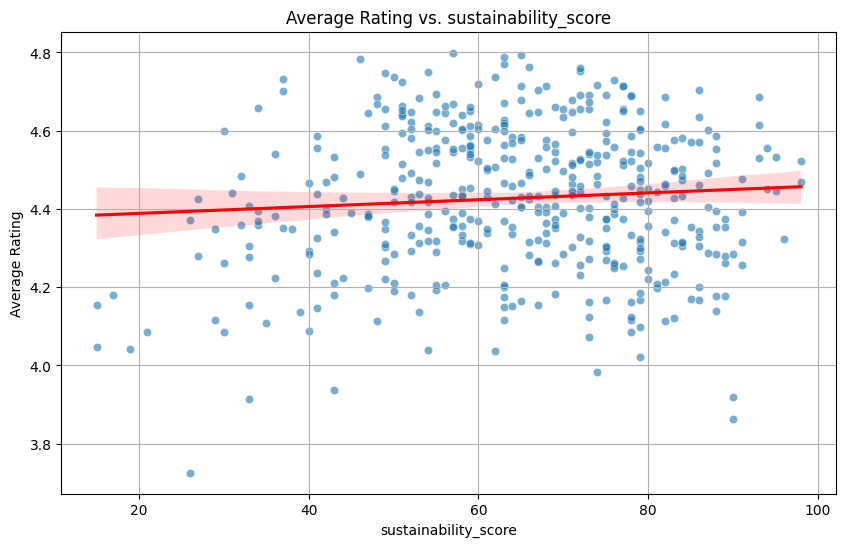

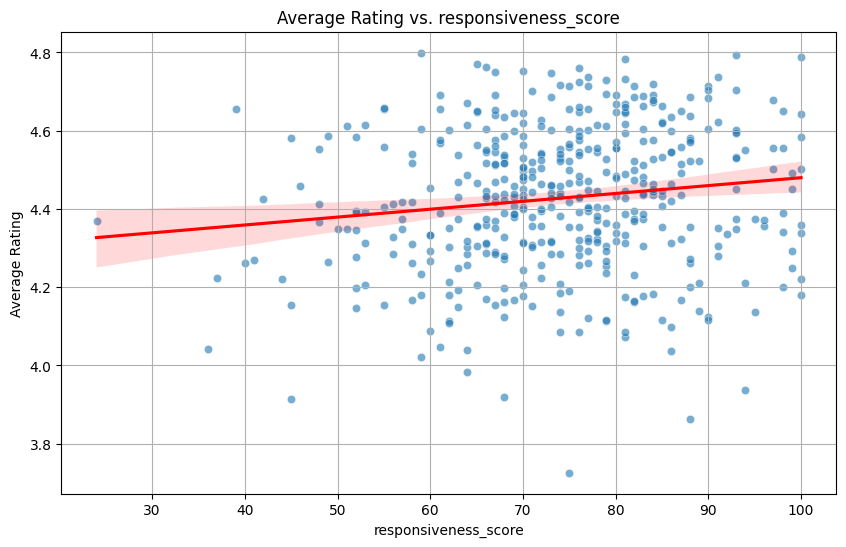

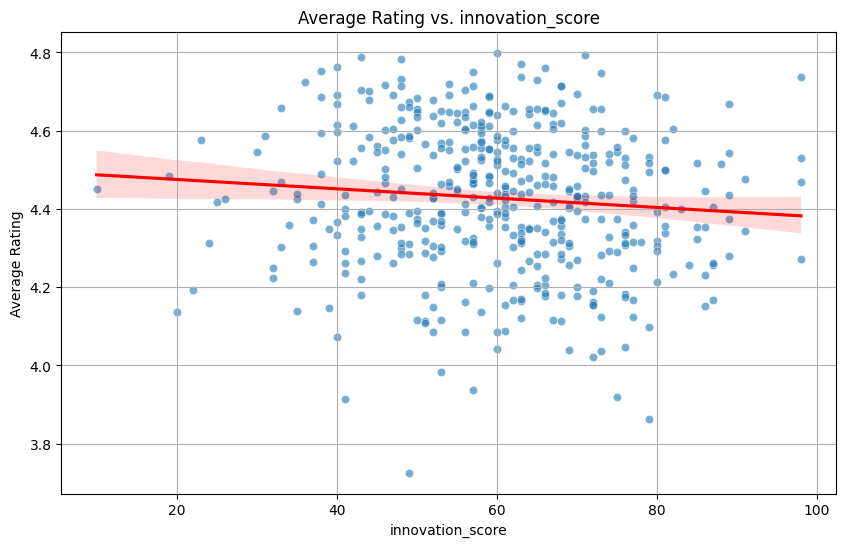

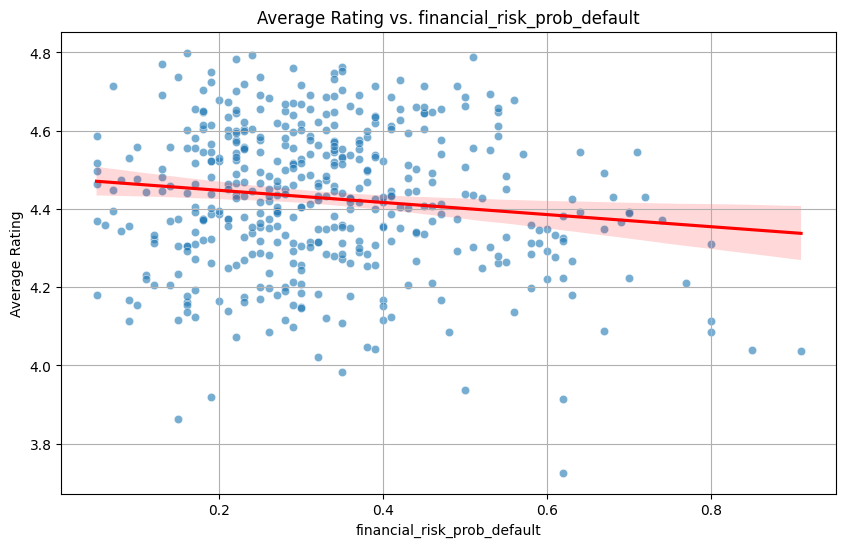

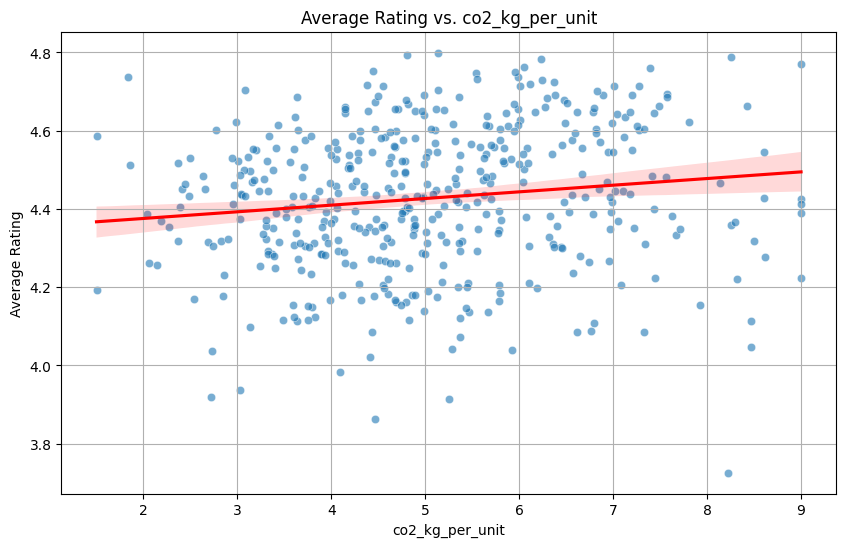

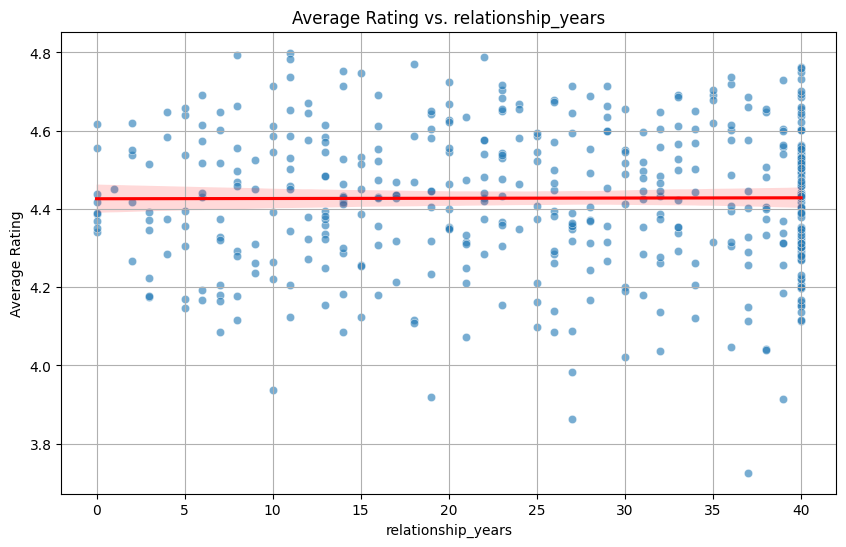

In [ ]:
try:
    suppliers_df = pd.read_excel("supplier_recommender_textile (1).xlsx", sheet_name='SUPPLIERS')
    events_df = pd.read_excel("supplier_recommender_textile (1).xlsx", sheet_name='EVENTS')
    interactions_df = pd.read_excel("supplier_recommender_textile (1).xlsx", sheet_name='INTERACTIONS')

    # 1. Distribuição da variável alvo (avg_rating)
    plt.figure(figsize=(10, 6))
    # Utilizando o suppliers_df, pois cada fornecedor tem um único avg_rating
    sns.histplot(suppliers_df['avg_rating'].dropna(), kde=True, bins=30)
    plt.title('Distribuição do Average Rating dos Fornecedores')
    plt.xlabel('Average Rating')
    plt.ylabel('Frequência')
    plt.grid(True)
    plt.savefig('avg_rating_distribution.png')
    print("Gráfico da distribuição do 'Average Rating' salvo como 'avg_rating_distribution.png'")

    # 2. Matriz de Correlação
    # Selecionando apenas as colunas numéricas do dataframe de fornecedores
    numerical_cols_supplier = suppliers_df.select_dtypes(include=['float64', 'int64']).columns
    correlation_matrix_supplier = suppliers_df[numerical_cols_supplier].corr()

    plt.figure(figsize=(18, 14))
    sns.heatmap(correlation_matrix_supplier, annot=True, fmt=".2f", cmap='coolwarm')
    plt.title('Matriz de Correlação de Features Numéricas (Average Rating)')
    plt.savefig('correlation_matrix_supplier.png')
    print("Matriz de correlação (nível fornecedor) salva como 'correlation_matrix_supplier.png'")

    # 3. Features Categóricas vs. Average Rating (Boxplots)
    # Usando o dataframe de fornecedores
    categorical_features_supplier = ['cluster', 'region', 'tier', 'performance_band', 'product_focus']
    for feature in categorical_features_supplier:
        plt.figure(figsize=(14, 8))
        # Para 'product_focus', que pode ter muitas categorias, ajustamos o gráfico
        if feature == 'product_focus':
            order = suppliers_df.groupby(feature)['avg_rating'].mean().sort_values(ascending=False).index
            sns.boxplot(x=feature, y='avg_rating', data=suppliers_df, order=order)
        else:
            sns.boxplot(x=feature, y='avg_rating', data=suppliers_df)

        plt.title(f'Average Rating vs. {feature}')
        plt.xlabel(feature)
        plt.ylabel('Average Rating')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.grid(True)
        plt.savefig(f'avg_rating_vs_{feature}.png')
        print(f"Gráfico de 'Average Rating' vs. {feature} salvo como 'avg_rating_vs_{feature}.png'")

    # 4. Gráficos de Dispersão para features numéricas importantes vs. Average Rating
    numerical_features_scatter_supplier = [
        'avg_lead_time_days', 'price_index_vs_market', 'defect_rate_pct',
        'sustainability_score', 'responsiveness_score', 'innovation_score',
        'financial_risk_prob_default', 'co2_kg_per_unit', 'relationship_years'
    ]

    for feature in numerical_features_scatter_supplier:
        plt.figure(figsize=(10, 6))
        sns.scatterplot(x=feature, y='avg_rating', data=suppliers_df, alpha=0.6)
        # Adiciona uma linha de tendência para visualizar melhor a relação
        sns.regplot(x=feature, y='avg_rating', data=suppliers_df, scatter=False, color='red')
        plt.title(f'Average Rating vs. {feature}')
        plt.xlabel(feature)
        plt.ylabel('Average Rating')
        plt.grid(True)
        plt.savefig(f'avg_rating_vs_{feature}_scatter.png')
        print(f"Gráfico de dispersão de 'Average Rating' vs. {feature} salvo como 'avg_rating_vs_{feature}_scatter.png'")

except FileNotFoundError as e:
    print(f"Erro: Arquivo não encontrado. Verifique se o nome e o caminho do arquivo estão corretos. Detalhes: {e}")
except Exception as e:
    print(f"Ocorreu um erro inesperado: {e}")

In [ ]:
suppliers_df = pd.read_excel("supplier_recommender_textile (1).xlsx", sheet_name='SUPPLIERS')

features_cols = [
    'relationship_years', 'avg_lead_time_days', 'price_index_vs_market',
    'defect_rate_pct', 'on_time_delivery_pct', 'sustainability_score',
    'responsiveness_score', 'innovation_score', 'financial_risk_prob_default'
]
target_col = 'avg_rating'

X = suppliers_df[features_cols]
y = suppliers_df[target_col]

# Removendo as linhas onde o 'avg_rating' é ausente
data = pd.concat([X, y], axis=1)
data.dropna(subset=[target_col], inplace=True)

# Atualizando X e y após remover as linhas com NaN no target
X = data[features_cols]
y = data[target_col]

imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# 2. Divisão, Treino e Previsão
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 3. Cálculo e Apresentação das Métricas
import numpy as np # Import numpy for sqrt
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse) # Calculate RMSE using np.sqrt

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.1008
MSE: 0.0171
RMSE: 0.1306
